# ReviewWise — Make every review count
**Veritas AI International High School Hackathon 2026 · AI + Finance**

**Team:** Bazlo Carp and Benton Vargo

A payment risk analyst may have thousands of transactions to check and time to investigate only a small fraction. ReviewWise asks a practical question: **if an analyst can review 1% of a batch, which transactions should come first?**

We use machine learning to build a review queue, then compare it with a simple rule: review the largest payments first. Being placed in either queue means a transaction deserves investigation. It does not establish fraud or automatically block a payment.

**To run this notebook:** choose **Runtime → Run all** in Colab using a standard CPU runtime. The public dataset downloads automatically, so you do not need API keys or a manual upload. The file is about 144 MB, and training can take several minutes. We print the package versions and elapsed time so you can see what ran. The longer, optional tuning experiment is off by default.

Everything needed for the main analysis is included here. The saved results were generated and checked locally; running all cells will reproduce the analysis in your Colab environment. Colab's runtime files are temporary, so save a copy of the notebook to Drive if you want to keep your edits and outputs.

**This project is a prototype and is not financial advice.**


## 1. Get to know the data
We use the public ULB/Worldline [credit-card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), which contains transactions from two days in 2013. This notebook loads it from the public mirror used by TensorFlow. We check the file's digital fingerprint, or hash, to make sure we are working with the expected data.

Each row describes one transaction:

- **V1–V28** are numerical features created using principal component analysis (PCA). They represent transformed combinations of the original information, whose business meanings are hidden. Their values can still contain patterns associated with fraud.
- **Amount** is the transaction amount.
- **Class** is the known historical outcome: 1 for fraud and 0 for legitimate. The model learns from these labels during training, but never receives Class as an input when scoring a transaction.
- **Time** records seconds since the first transaction in the dataset. We use it to put transactions in order, rather than as a prediction feature.

Because the features are anonymous, we cannot claim that a particular value identifies a merchant, location, or reason for fraud.


In [1]:
import hashlib, json, platform, time, warnings, urllib.request
from pathlib import Path
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import auc, average_precision_score, precision_recall_curve

started = time.perf_counter()
versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','matplotlib']}
print('Python:', platform.python_version(), '\nPackages:', versions)
FEATURES = [f'V{i}' for i in range(1,29)] + ['Amount']
REQUIRED = ['Time', *FEATURES, 'Class']
DATA_URL = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
EXPECTED_HASH = '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89'
data_path = Path('data/creditcard.csv')
data_path.parent.mkdir(exist_ok=True)
if not data_path.exists():
    temporary = data_path.with_suffix('.download')
    with urllib.request.urlopen(DATA_URL, timeout=120) as response, temporary.open('wb') as target:
        while chunk := response.read(1024 * 1024):
            target.write(chunk)
    temporary.replace(data_path)
with data_path.open('rb') as source:
    digest = hashlib.file_digest(source, 'sha256').hexdigest()
if digest != EXPECTED_HASH:
    raise ValueError('Dataset hash differs. Remove the cached CSV and verify the public source before rerunning.')
print('Verified public dataset:', digest)


Python: 3.12.14 
Packages: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}
Verified public dataset: 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89


## 2. Learn from the past and check on later transactions
In real use, an analyst would learn from past transactions before reviewing new ones. We follow that order here: roughly the earliest 60% is used for training, the next 20% for validation, and the final 20% for testing.

Validation helps us choose between models. The test set is reserved for evaluating the selected approach. Transactions with the same timestamp stay together. We choose the group boundaries nearest the 60% and 80% marks, using the earlier boundary if two are equally close. Each split must contain both legitimate and fraudulent transactions.

We also scale the input features for logistic regression. Scaling learns a mean and standard deviation for each feature, so it is part of the training process. We calculate those values from training rows only and apply the same transformation to later rows. Otherwise, information from later transactions would leak into training.

Some transactions share identical input values across splits. We keep them in the original experiment and report the overlap below, because it limits what we can say about performance on unfamiliar transactions.


In [2]:
def validate(frame):
    missing = sorted(set(REQUIRED) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing required CSV columns: {', '.join(missing)}")
    if frame.empty:
        raise ValueError("The CSV contains no transactions.")
    data = frame[REQUIRED].copy()
    for column in REQUIRED:
        data[column] = pd.to_numeric(data[column], errors="raise")
    if not np.isfinite(data.to_numpy(dtype=float)).all():
        raise ValueError("Required columns contain missing or infinite values; fix the input.")
    if not data["Class"].isin([0, 1]).all():
        raise ValueError("Class must contain only 0 (legitimate) and 1 (fraud).")
    if (data[["Time", "Amount"]] < 0).any().any():
        raise ValueError("Time and Amount must be nonnegative.")
    data["Class"] = data["Class"].astype(int)
    data.insert(0, "transaction_id", np.arange(1, len(data) + 1))
    return data.sort_values(["Time", "transaction_id"], kind="stable").reset_index(drop=True)

def split_data(data):
    """Choose the nearest interior timestamp-group boundary; ties go earlier."""
    times = data["Time"].to_numpy()
    boundaries = np.flatnonzero(times[:-1] != times[1:]) + 1
    if len(boundaries) < 2:
        raise ValueError("Need at least three distinct timestamps to create three splits.")
    # Integer distances avoid rounding ambiguity at the 60% and 80% targets.
    cuts = [int(boundaries[np.argmin(abs(boundaries * 5 - len(data) * numerator))])
            for numerator in (3, 4)]
    if cuts[0] >= cuts[1]:
        raise ValueError("Nearest timestamp boundaries do not form three nonempty splits.")
    splits = {
        "train": data.iloc[:cuts[0]].copy(),
        "validation": data.iloc[cuts[0]:cuts[1]].copy(),
        "test": data.iloc[cuts[1]:].copy(),
    }
    for name, rows in splits.items():
        if set(rows["Class"]) != {0, 1}:
            raise ValueError(f"The fixed {name} split does not contain both classes; cannot evaluate this design.")
    return splits

def describe_splits(splits):
    return {
        name: {
            "rows": len(rows), "fraud": int(rows["Class"].sum()),
            "legitimate": int((rows["Class"] == 0).sum()),
            "fraud_prevalence": float(rows["Class"].mean()),
            "time_min": float(rows["Time"].min()),
            "time_max": float(rows["Time"].max()),
            "membership_sha256": hashlib.sha256(
                rows["transaction_id"].to_numpy(dtype="<i8").tobytes()).hexdigest(),
        }
        for name, rows in splits.items()
    }

def audit_data(data, splits):
    # Exact merges on distinct vectors, not approximate hash matches.
    unique = {name: rows[FEATURES].drop_duplicates() for name, rows in splits.items()}
    overlap = {}
    for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
        overlap[f"{left}__{right}"] = len(unique[left].merge(unique[right], on=FEATURES))
    return {
        "rows": len(data), "fraud": int(data["Class"].sum()),
        "exact_duplicate_rows_beyond_first": int(data.duplicated(REQUIRED).sum()),
        "identical_feature_vectors_across_splits": overlap,
        "splits": describe_splits(splits),
    }


In [3]:
data = validate(pd.read_csv(data_path))
splits = split_data(data)
train, validation, test = (splits[name] for name in ['train','validation','test'])
audit = audit_data(data, splits)
display(pd.DataFrame(audit['splits']).T.drop(columns='membership_sha256'))
print('Exact duplicate rows beyond the first:', audit['exact_duplicate_rows_beyond_first'])
print('Distinct shared input vectors:', audit['identical_feature_vectors_across_splits'])
print(f"Always predicting legitimate would be {(data.Class == 0).mean():.2%} accurate while catching zero fraud.")


,rows,fraud,legitimate,fraud_prevalence,time_min,time_max
train,170882,360,170522,0.002107,0.0,120395.0
validation,56964,57,56907,0.001001,120396.0,145248.0
test,56961,75,56886,0.001317,145249.0,172792.0


Exact duplicate rows beyond the first: 1081
Distinct shared input vectors: {'train__validation': 274, 'train__test': 312, 'validation__test': 872}
Always predicting legitimate would be 99.83% accurate while catching zero fraud.


## 3. Compare models at the same review budget
A model could label every transaction legitimate and achieve very high accuracy, simply because fraud is rare. That would be useless for finding fraud. Our main measure is therefore **how much fraud we catch when the number of reviews is fixed**.

At a 1% budget, every ranking gets 1% of the batch, rounded up to a whole transaction. For example, 56,961 transactions allow 570 reviews. If scores tie, the transaction with the smaller original row ID comes first. That ID keeps the ranking consistent; it is never a model feature.

We report several measures because each answers a different question:

- **Recall:** Of all the fraud in the batch, how much did we catch?
- **Precision:** Of the transactions sent for review, how many were actually fraud?
- **False positives (FP):** How many legitimate transactions required review?
- **False negatives (FN):** How many fraudulent transactions were missed?
- **Average precision (AP) and trapezoidal PR-AUC:** How well does the model rank fraud across different cutoffs? These summarize the precision–recall relationship in different ways, so we label them separately.

The largest-payment rule receives exactly the same number of reviews. We also show what happens when nothing is flagged: no work, but no fraud caught. That is an illustration, rather than an equal-budget competitor. When a metric is undefined, we leave it undefined; for example, precision cannot be calculated when nothing is reviewed.


In [4]:
def review_count(n, capacity_units):
    """One unit = 0.1%. Integer ceiling avoids an accidental extra review."""
    if not isinstance(capacity_units, (int, np.integer)) or not 0 <= capacity_units <= 1000:
        raise ValueError("Capacity must be an integer from 0 through 1000 tenths of a percent.")
    if n < 0:
        raise ValueError("Batch size cannot be negative.")
    return min(n, (n * int(capacity_units) + 999) // 1000)

def rank_order(scores, ids):
    scores, ids = np.asarray(scores), np.asarray(ids)
    if scores.ndim != 1 or ids.ndim != 1:
        raise ValueError("Scores and transaction IDs must be one-dimensional vectors.")
    if len(scores) != len(ids) or len(set(ids)) != len(ids):
        raise ValueError("Scores require an equal-length vector of unique transaction IDs.")
    if not np.isfinite(scores).all():
        raise ValueError("Ranking scores must be finite.")
    return np.lexsort((ids, -scores))

def selection(scores, ids, capacity_units):
    chosen = np.zeros(len(scores), dtype=bool)
    chosen[rank_order(scores, ids)[:review_count(len(scores), capacity_units)]] = True
    return chosen

def counts(labels, selected):
    labels, selected = np.asarray(labels), np.asarray(selected, dtype=bool)
    if labels.ndim != 1 or selected.ndim != 1:
        raise ValueError("Labels and selections must be one-dimensional vectors.")
    if len(labels) != len(selected) or not np.isin(labels, [0, 1]).all():
        raise ValueError("Metrics require aligned binary labels and selections.")
    fraud = labels == 1
    tp, fp = int((fraud & selected).sum()), int((~fraud & selected).sum())
    fn, tn = int((fraud & ~selected).sum()), int((~fraud & ~selected).sum())
    return {
        "n": len(labels), "k": tp + fp, "fraud": tp + fn,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision": tp / (tp + fp) if tp + fp else None,
        "recall": tp / (tp + fn) if tp + fn else None,
    }

def ranking_metrics(labels, scores):
    if not np.any(np.asarray(labels) == 1):
        return {"average_precision": None, "pr_auc_trapezoidal": None}
    precision, recall, _ = precision_recall_curve(labels, scores)
    return {
        "average_precision": float(average_precision_score(labels, scores)),
        "pr_auc_trapezoidal": float(auc(recall, precision)),
    }

def capacity_results(labels, scores, ids, capacities=range(1, 51)):
    return [
        {"capacity_units": int(c), **counts(labels, selection(scores, ids, c))}
        for c in capacities
    ]

def temporal_results(labels, times, selected, edges):
    """Attribute the original global selections; never reallocate per window."""
    times, labels, selected = np.asarray(times), np.asarray(labels), np.asarray(selected)
    if len(edges) != 4 or np.any(np.diff(edges) <= 0):
        raise ValueError("Temporal analysis needs three positive-duration windows.")
    if len(times) != len(labels) or len(times) != len(selected):
        raise ValueError("Temporal arrays must align.")
    if len(times) and (times.min() < edges[0] or times.max() > edges[-1]):
        raise ValueError("Temporal windows do not cover the batch.")
    windows = np.searchsorted(np.asarray(edges)[1:-1], times, side="right")
    return [
        {"window": i + 1, "start": float(edges[i]), "end": float(edges[i + 1]),
         **counts(labels[windows == i], selected[windows == i])}
        for i in range(3)
    ]


## 4. Train two models and choose on validation data
We compare two approaches.

**Logistic regression** learns a weight for each standardized input feature. It multiplies each feature value by its weight, adds the contributions and an intercept, then converts the total into a score between 0 and 1. A positive weight raises the score as that feature increases, while a negative weight lowers it, holding the other features constant. The combination matters: no single V-value automatically means fraud.

**Random forest** combines many decision trees. Each tree learns rules that split transactions according to their feature values. The forest averages the trees' predictions to produce its score.

Both approaches use class balancing to give the rare fraud examples more influence during training. We then compare their validation recall at the same 1% review budget. If they catch the same share of fraud, we choose logistic regression for simplicity. The settings below are the original baseline settings, and the test set is not scored in this step.

We use the resulting scores to decide review order. We have not calibrated them or verified their accuracy as probabilities, so a score of 0.9 should not be read as a confirmed 90% chance of fraud.


In [5]:
parameters = {
    'logistic_regression': dict(C=1.0, class_weight='balanced', solver='lbfgs', max_iter=2000, random_state=42),
    'random_forest': dict(n_estimators=200, max_depth=12, min_samples_leaf=5,
                          class_weight='balanced_subsample', n_jobs=-1, random_state=42),
}
models = {
    'logistic_regression': make_pipeline(StandardScaler(), LogisticRegression(**parameters['logistic_regression'])),
    'random_forest': RandomForestClassifier(**parameters['random_forest']),
}
validation_results = {}
for name, model in models.items():
    tick = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        model.fit(train[FEATURES], train.Class)
    scores = model.predict_proba(validation[FEATURES])[:,1]
    validation_results[name] = {**counts(validation.Class, selection(scores, validation.transaction_id, 10)),
                                **ranking_metrics(validation.Class, scores)}
    print(f'{name}: fitted and validated in {time.perf_counter()-tick:.1f} seconds')
selected_model = ('random_forest' if validation_results['random_forest']['recall'] >
                  validation_results['logistic_regression']['recall'] else 'logistic_regression')
display(pd.DataFrame(validation_results).T)
print('Frozen selected model:', selected_model)


logistic_regression: fitted and validated in 0.6 seconds


random_forest: fitted and validated in 72.3 seconds


,n,k,fraud,tp,fp,fn,tn,precision,recall,average_precision,pr_auc_trapezoidal
logistic_regression,56964.0,570.0,57.0,49.0,521.0,8.0,56386.0,0.085965,0.859649,0.772324,0.771922
random_forest,56964.0,570.0,57.0,48.0,522.0,9.0,56385.0,0.084211,0.842105,0.766606,0.766028


Frozen selected model: logistic_regression


## 5. Check the selected approach on the test batch
The model choice is now fixed. The next cell scores the later test transactions and compares both models with the largest-payment rule. The models retain what they learned from the training rows; we do not retrain them on validation data.

Our headline result stays with the model chosen on validation, even if the other model has a higher test AP. Switching after seeing test results would make the evaluation part of the selection process.

These historical test outcomes have already been examined during project development. They remain useful for describing this experiment, but any future claim of improvement needs confirmation on fresh, untouched data.


In [6]:
test_scores = {name: model.predict_proba(test[FEATURES])[:,1] for name, model in models.items()}
test_scores['amount'] = test.Amount.to_numpy()
ids, labels = test.transaction_id.to_numpy(), test.Class.to_numpy()
result_rows = []
for name, scores in test_scores.items():
    for budget in [5,10,20]:
        result_rows.append({'method':name, 'capacity_percent':budget/10,
                           **counts(labels, selection(scores, ids, budget)), **ranking_metrics(labels,scores)})
results = pd.DataFrame(result_rows)
display(results[results.capacity_percent == 1].reset_index(drop=True))
print('Flag nothing:', counts(labels, np.zeros(len(labels), dtype=bool)))
headline = results[(results.method == selected_model) & (results.capacity_percent == 1)].iloc[0]
amount_result = results[(results.method == 'amount') & (results.capacity_percent == 1)].iloc[0]
print(f"With {int(headline.k)} reviews, {selected_model} caught {int(headline.tp)} of {int(headline.fraud)} frauds, "
      f"versus {int(amount_result.tp)} for largest payments. "
      f"There were {int(headline.fp)} legitimate reviews and {int(headline.fn)} missed frauds.")


,method,capacity_percent,n,k,fraud,tp,fp,fn,tn,precision,recall,average_precision,pr_auc_trapezoidal
0,logistic_regression,1.0,56961,570,75,65,505,10,56381,0.114035,0.866667,0.745104,0.743201
1,random_forest,1.0,56961,570,75,65,505,10,56381,0.114035,0.866667,0.812557,0.812304
2,amount,1.0,56961,570,75,3,567,72,56319,0.005263,0.040000,0.001448,0.001336


Flag nothing: {'n': 56961, 'k': 0, 'fraud': 75, 'tp': 0, 'fp': 0, 'fn': 75, 'tn': 56886, 'precision': None, 'recall': 0.0}
With 570 reviews, logistic_regression caught 65 of 75 frauds, versus 3 for largest payments. There were 505 legitimate reviews and 10 missed frauds.


## 6. What does more review time buy?
Finding suspicious transactions is only part of the problem. An analyst also needs to know whether reviewing more transactions is worth the extra effort.

We compare budgets of 0.5%, 1%, and 2%. The table shows both the fraud caught and the legitimate transactions reviewed. It also shows how many additional reviews are needed for any additional fraud caught when moving to the next budget.

The 1% budget is our working assumption; we have not checked it with a real review team. Likewise, the amount of a fraudulent transaction is not automatically money saved. This experiment measures prioritization, not the financial outcome of an investigation.


,capacity_percent,k,tp,fp,fn,precision,recall,extra_reviews,extra_frauds_caught
0,0.5,285,64,221,11,0.224561,0.853333,NaN,NaN
1,1.0,570,65,505,10,0.114035,0.866667,285.0,1.0
2,2.0,1140,66,1074,9,0.057895,0.880000,570.0,1.0


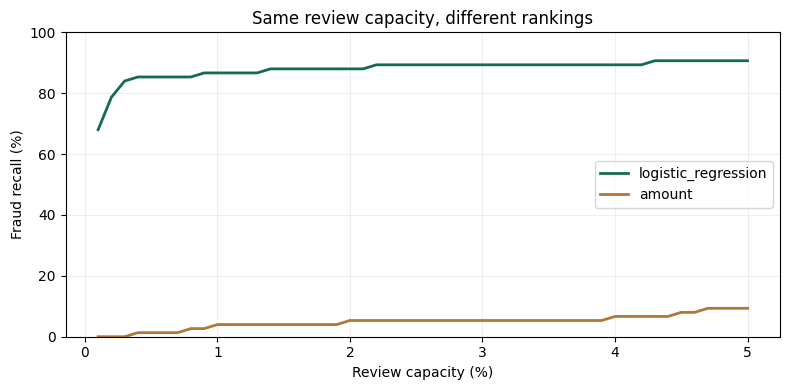

In [7]:
budget_table = results[results.method == selected_model].sort_values('capacity_percent').copy()
budget_table['extra_reviews'] = budget_table.k.diff()
budget_table['extra_frauds_caught'] = budget_table.tp.diff()
display(budget_table[['capacity_percent','k','tp','fp','fn','precision','recall','extra_reviews','extra_frauds_caught']])
fig, ax = plt.subplots(figsize=(8,4))
for name, color in [(selected_model,'#136B50'),('amount','#B07834')]:
    curve = pd.DataFrame(capacity_results(labels,test_scores[name],ids))
    ax.plot(curve.capacity_units/10,curve.recall*100,label=name,color=color,linewidth=2)
ax.set(xlabel='Review capacity (%)',ylabel='Fraud recall (%)',ylim=(0,100),title='Same review capacity, different rankings')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()


## 7. Does the overall result hide a weaker period?
One average can hide variation. To look more closely, we divide the test batch into three equal-duration periods and show where the reviews and errors occurred.

We keep the original top-1% queue for the whole batch and count its results within each period. We do not create three new queues. This lets us see how the same review policy performed over time, including how unevenly it allocated review slots.

The dataset is short and some periods contain very few frauds. A weaker period is worth reporting, but it does not prove a lasting change in fraud patterns. We also do not use this test breakdown to retune the models.


In [8]:
edges = np.linspace(test.Time.min(), test.Time.max(), 4)
temporal = pd.DataFrame([{'method':name,**row} for name in [selected_model,'amount']
    for row in temporal_results(labels,test.Time,selection(test_scores[name],ids,10),edges)])
display(temporal)
for name in [selected_model,'amount']:
    window_totals = temporal[temporal.method == name][['k','tp','fp','fn']].sum()
    global_counts = counts(labels,selection(test_scores[name],ids,10))
    assert all(window_totals[key] == global_counts[key] for key in window_totals.index)
print('Window counts reconcile with the global queues.')


,method,window,start,end,n,k,fraud,tp,fp,fn,tn,precision,recall
0,logistic_regression,1,145249.0,154430.0,21634,214,38,35,179,3,21417,0.163551,0.921053
1,logistic_regression,2,154430.0,163611.0,19786,206,26,23,183,3,19577,0.111650,0.884615
2,logistic_regression,3,163611.0,172792.0,15541,150,11,7,143,4,15387,0.046667,0.636364
3,amount,1,145249.0,154430.0,21634,267,38,3,264,35,21332,0.011236,0.078947
4,amount,2,154430.0,163611.0,19786,183,26,0,183,26,19577,0.000000,0.000000
5,amount,3,163611.0,172792.0,15541,120,11,0,120,11,15410,0.000000,0.000000


Window counts reconcile with the global queues.


## 8. Explore the queue and its mistakes
Even a useful ranking makes mistakes. A legitimate payment can receive a high score, while a fraud can rank below the review cutoff. The anonymous features let us measure those errors, but they do not give us a reliable business explanation for each one.

Run the cell below, choose a budget, and click **Show review queues**. You will see the first 15 transactions in each queue. The reported metrics still cover every selected transaction, not just those visible rows.

Click **Reveal historical outcomes** to see which transactions were actually labeled fraudulent. The demo also identifies the highest-ranked legitimate review and missed fraud, when those examples exist, and shows how many reviews would be needed to reach them.

Changing the budget hides the outcomes again and changes the queue size. It does not retrain the model. Individual transaction previews are generated when you use the controls; they are not saved in the initial submission outputs.


In [9]:
import ipywidgets as widgets
budget_widget = widgets.Dropdown(options=[('0.5%',5),('1%',10),('2%',20)],value=10,description='Budget:')
show_button = widgets.Button(description='Show review queues')
reveal_button = widgets.Button(description='Reveal historical outcomes',layout=widgets.Layout(width='230px'))
output_widget = widgets.Output()

def show_queues(reveal=False):
    with output_widget:
        clear_output(wait=True)
        units = budget_widget.value
        k = review_count(len(test),units)
        print(f'{k} reviews per strategy. Preview: first 15 rows. Scores are not calibrated probabilities.')
        for name in [selected_model,'amount']:
            positions = rank_order(test_scores[name],ids)[:k]
            preview = test.iloc[positions[:15]][['transaction_id','Time','Amount']].copy()
            preview.insert(0,'Rank',np.arange(1,len(preview)+1))
            if name != 'amount': preview['Model score'] = test_scores[name][positions[:15]]
            if reveal: preview['Historical outcome'] = labels[positions[:15]]
            print(name); display(preview)
            if reveal: print(counts(labels,selection(test_scores[name],ids,units)))
        if reveal:
            order = rank_order(test_scores[selected_model],ids)
            for title, mask in [('Highest-ranked legitimate review',(labels[order[:k]] == 0)),
                                ('Highest-ranked missed fraud',(labels[order[k:]] == 1))]:
                found = np.flatnonzero(mask)
                if len(found):
                    rank = int(found[0]+1+(k if 'missed' in title else 0))
                    print(f'{title}: rank {rank}; at least {rank} reviews needed to reach this transaction.')
                else: print(title + ': none at this budget.')

show_button.on_click(lambda _: show_queues(False))
reveal_button.on_click(lambda _: show_queues(True))
budget_widget.observe(lambda change: show_queues(False),names='value')
display(widgets.VBox([budget_widget,widgets.HBox([show_button,reveal_button]),output_widget]))
print('Click a button above to inspect the batch. This interaction is for presentation, not access control.')


Click a button above to inspect the batch. This interaction is for presentation, not access control.


## 9. What we tried—and why we kept the baseline
We tried to improve the model rather than assuming its first settings were best. We tested five values of logistic regression's regularization setting, C: 1, 0.01, 0.1, 10, and 100. For the random forest, we compared the baseline with a shallower forest, a deeper forest, and a smaller minimum leaf size.

Every logistic configuration caught **49 of 57 validation frauds with 570 reviews**. The forests caught 47 or 48. C=10 produced a tiny increase in average precision, but caught no additional fraud at our chosen budget. We therefore kept the original logistic setting, C=1. The search gave us no evidence of improvement on our main measure.

Those figures come from the earlier development experiments. The optional cell below repeats the search using training and validation data only. It does not replace the models or selection used in the main analysis. With only 57 validation frauds, repeatedly trying settings could eventually fit quirks of this particular validation set.

We also checked the baseline across three later windows of development data, expanding the training history before each window. It caught **40/52, 91/102, and 45/52** frauds. Excluding input vectors already seen in each window's training history left those fraud counts unchanged, although the number of transactions and review slots changed. This checks sensitivity to repeated feature values; it does not establish that we removed repeat customers, whose identities are unavailable.

[Full tuning results](https://github.com/bento-v/hackathonproject/blob/main/TUNING_RESULTS.md) · [Audit results](https://github.com/bento-v/hackathonproject/blob/main/results/validation_audit.json)


In [10]:
RUN_OPTIONAL_SEARCH = False
if RUN_OPTIONAL_SEARCH:
    from copy import deepcopy
    candidates = []
    for c in [1,.01,.1,10,100]:
        settings = dict(parameters['logistic_regression'],C=c)
        candidates.append((f'Logistic C={c}',make_pipeline(StandardScaler(),LogisticRegression(**settings))))
    for depth,leaf in [(12,5),(8,5),(16,5),(12,1)]:
        settings = dict(parameters['random_forest'],max_depth=depth,min_samples_leaf=leaf)
        candidates.append((f'Forest depth={depth} leaf={leaf}',RandomForestClassifier(**settings)))
    search_rows = []
    for name,candidate in candidates:
        with warnings.catch_warnings():
            warnings.simplefilter('error',ConvergenceWarning)
            candidate.fit(train[FEATURES],train.Class)
        scores = candidate.predict_proba(validation[FEATURES])[:,1]
        search_rows.append({'candidate':name,**counts(validation.Class,selection(scores,validation.transaction_id,10)),
                            **ranking_metrics(validation.Class,scores)})
    display(pd.DataFrame(search_rows))
else:
    print('Optional search skipped. Baseline models and headline selection are unchanged.')


Optional search skipped. Baseline models and headline selection are unchanged.


## 10. What we checked, and what remains uncertain
The checks below help catch implementation mistakes. They confirm that scaling uses training rows, the splits follow time order, both rankings receive the same review budget, and the error counts add up correctly. Passing these checks means the code follows our intended rules; it does not guarantee future accuracy.

The biggest limitation is the data. It covers only two days in 2013, contains anonymous features, and includes repeated input vectors across splits. There are also relatively few fraud examples in validation. We have not established calibrated probabilities, demographic fairness, or reliability in a live payment system, and we have not tested the tool with analysts.

A useful next step would be to ask analysts what review capacity and error tradeoffs make sense for their work. We would then evaluate a fixed policy on independently sourced data with compatible features. That compatibility matters: PCA columns from a different transformation cannot simply be treated as the same V1–V28 inputs.

Our result supports a narrower conclusion: on this historical batch, a learned ranking helped direct a limited number of reviews toward more fraud than the largest-payment rule.

**This project is a prototype and is not financial advice.**


In [11]:
assert train.Time.max() < validation.Time.min() < test.Time.min()
assert validation.Time.max() < test.Time.min()
assert not {'Class','Time','transaction_id'} & set(FEATURES)
np.testing.assert_allclose(models['logistic_regression'][0].mean_,train[FEATURES].mean())
assert review_count(10000,7) == 70
np.testing.assert_array_equal(rank_order([.5,.5,.9],[7,2,9]),[2,1,0])
for row in result_rows:
    assert row['n'] == row['tp']+row['fp']+row['fn']+row['tn']
    assert row['k'] == review_count(len(test),int(row['capacity_percent']*10))
    assert row['k'] == row['tp']+row['fp']
for name in test_scores:
    caught = results[results.method == name].sort_values('capacity_percent').tp.to_numpy()
    assert np.all(np.diff(caught) >= 0)
print('All correctness checks passed.')
print(f'Total run time: {time.perf_counter()-started:.1f} seconds (includes data loading and model fitting).')


All correctness checks passed.
Total run time: 77.7 seconds (includes data loading and model fitting).


## Sources, authorship, and final checks
- **Dataset:** ULB / Worldline [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud), loaded from the [TensorFlow public mirror](https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv).
- **Libraries:** Python, pandas, NumPy, scikit-learn, Matplotlib, IPython, and ipywidgets.
- **AI assistance:** OpenAI Codex assisted with planning, implementation, code review, experiments, testing, documentation, and this notebook. Before submitting, both team members should review the work and be able to explain its methods, results, and limitations.
- **Presentation reference:** Veritas AI's ScamCheck sample helped guide the notebook's structure. ReviewWise uses a different dataset and focuses on transaction review budgets.
- **Supporting repository:** https://github.com/bento-v/hackathonproject

Before submitting, run all cells in Colab and check the results. Save your copy to Drive, clear any individual transaction previews, and set sharing to **Anyone with the link → Viewer**. Check that the link opens in a private browser window. Finally, confirm your team details and the official submission requirements, then submit the required links through the competition form.
